In [1]:
import pandas  as pd
import numpy as np

In [2]:
df = pd.read_csv('placement.csv')

In [4]:
df.head()

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57


In [19]:
x = df.drop("package", axis=1)
y = df['package']

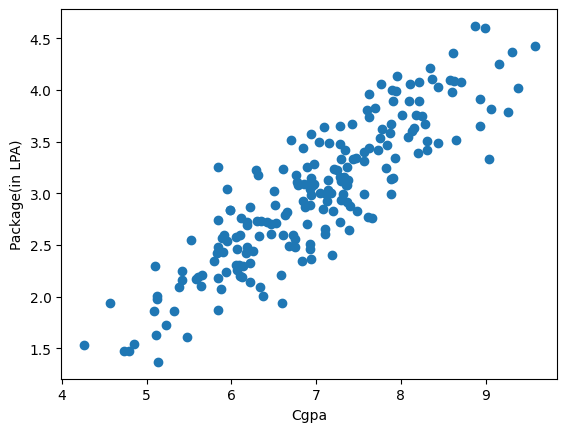

In [ ]:
import matplotlib.pyplot as plt
plt.scatter(x=df['cgpa'], y=df['package'])
plt.xlabel("Cgpa")
plt.ylabel("Package(in LPA)")

plt.show()

In [20]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=2)

In [21]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

In [22]:
lr.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [23]:
y_pred = lr.predict(x_test)

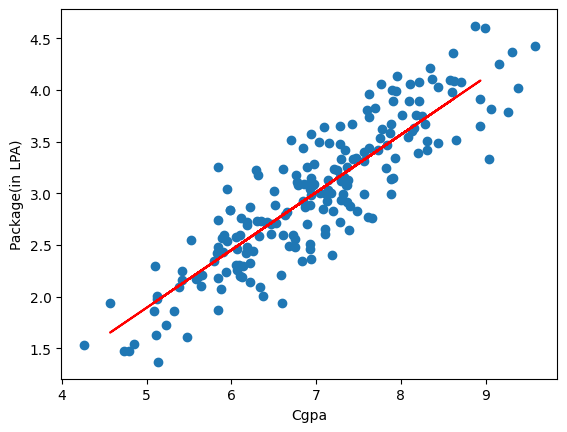

In [24]:
plt.scatter(x=df['cgpa'], y=df['package'])
plt.plot(x_test, y_pred, color= 'red')
plt.xlabel("Cgpa")
plt.ylabel("Package(in LPA)")

plt.show()

In [25]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error

In [26]:
print("MAE: ", mean_absolute_error(y_test, y_pred))

MAE:  0.2884710931878175


In [27]:
print("MSE: ", mean_squared_error(y_test, y_pred))

MSE:  0.12129235313495527


In [28]:
print("RMSE: ", root_mean_squared_error(y_test, y_pred))

RMSE:  0.34827051717731616


In [30]:
print("R2 SCORE: ", r2_score(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

R2 SCORE:  0.780730147510384


In [31]:
# Adjusted R2
x_test.shape

(40, 1)

In [34]:
print("Adjusted R2 :",1- (1-r2)*(40-1)/(40-1-1))

Adjusted R2 : 0.7749598882343415


## Randomly Adding New Column

In [35]:
new_df = df.copy()
new_df['random_feature'] = np.random.random(200)

new_df = new_df[['cgpa','random_feature','package']]
new_df.head()

,cgpa,random_feature,package
0,6.89,0.281089,3.26
1,5.12,0.939952,1.98
2,7.82,0.361187,3.25
3,7.42,0.113532,3.67
4,6.94,0.222474,3.57


In [36]:
x = new_df.iloc[:,0:2]
y = new_df.iloc[:,2]


In [38]:
print(x.shape)
print(y.shape)

(200, 2)
(200,)


In [39]:
from sklearn.model_selection import train_test_split
x_train , x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=2)


In [40]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [41]:
y_pred = lr.predict(x_test)

In [42]:
print("MAE: ", mean_absolute_error(y_test, y_pred))


MAE:  0.28900706083441347


In [43]:
print("R2 SCORE: ", r2_score(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

R2 SCORE:  0.7734530677158831


In [44]:
print("Adjusted R2 :",1- (1-r2)*(40-1)/(40-1-2))

Adjusted R2 : 0.7612072875924173
